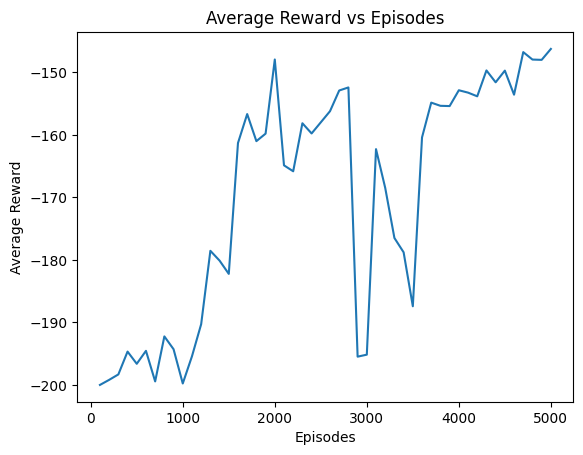

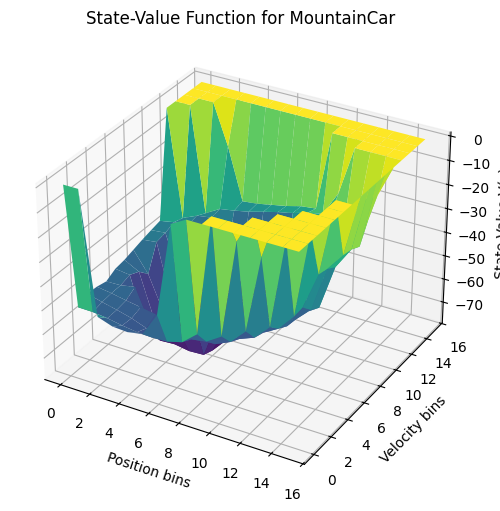

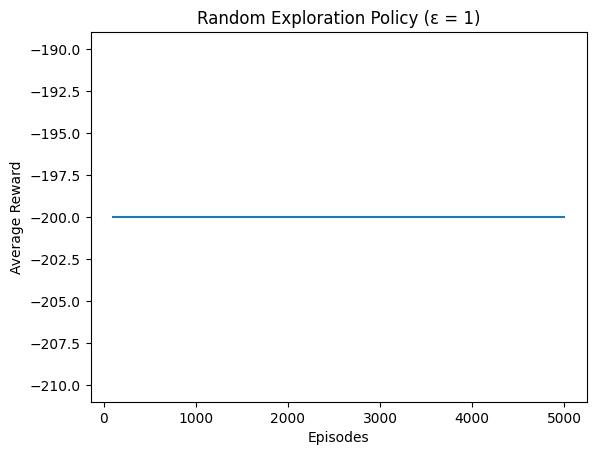

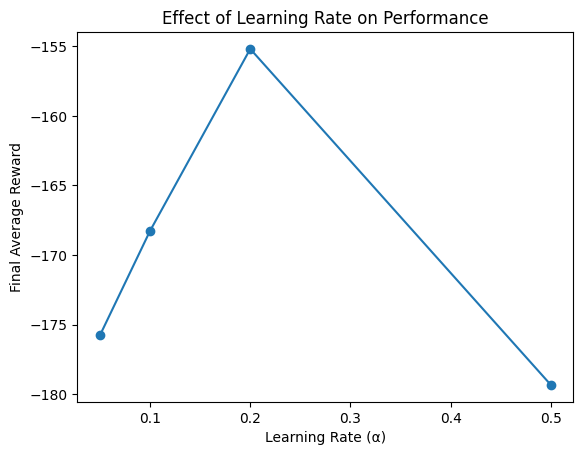

In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import math

# constants¬
position_dims = 15
velocity_dims = 15
show_last_episodes = 5
initiate_with_zeros = True


class QLearner:
    def __init__(self, learning, discount):
        # Import and initialize Mountain Car Environment
        self.env = gym.make('MountainCar-v0')
        self.env.reset()
        # Initialize learning rate (alpha) and discount value (gamma)
        self.learning = learning
        self.discount = discount
        # Down-scaling feature space to discrete range, determine number of discrete states
        self.ranges = self.env.observation_space.high - self.env.observation_space.low
        self.num_states = np.array([position_dims, velocity_dims])

        # Initiate Q-table with uniform random variables in [-1, 1] -> zeros is definitly better
        if initiate_with_zeros:
            self.Q = np.zeros((self.num_states[0] + 1, self.num_states[1] + 1, self.env.action_space.n))
        else:
            self.Q = np.random.uniform(low=-1, high=1,
                                       size=(self.num_states[0] + 1, self.num_states[1] + 1, self.env.action_space.n))

    # Get discrete representation of state
    def discretize_state(self, state):
        ratios = (state - self.env.observation_space.low) / self.ranges
        disc_state = (ratios * self.num_states).astype(int)
        return np.clip(disc_state, 0, self.num_states)

    # Determine next action using epsilon-greedy approach
    def get_action(self, disc_state, epsilon):
        return self.env.action_space.sample() if np.random.random() > 1 - epsilon else np.argmax(
            self.Q[disc_state[0], disc_state[1]])

    # Adjust Q value for current state
    def update_q(self, disc_state, action, disc_new_state, reward):
        best_future = np.max(self.Q[disc_new_state[0], disc_new_state[1]])
        self.Q[disc_state[0], disc_state[1], action] += \
            self.learning * (reward + self.discount * best_future -
                            self.Q[disc_state[0], disc_state[1], action])

    # Q-Learning function
    def q_learning(self, epsilon, min_eps, episodes):
        # Initialize variables to track rewards
        reward_list = []
        ave_reward_list = []

        for ep in range(episodes):
            state, _ = self.env.reset()
            disc_state = self.discretize_state(state)
            done = False
            total_reward = 0

            while not done:
                action = self.get_action(disc_state, epsilon)
                new_state, reward, terminated, truncated, _ = self.env.step(action)
                done = terminated or truncated

                disc_new_state = self.discretize_state(new_state)
                self.update_q(disc_state, action, disc_new_state, reward)

                disc_state = disc_new_state
                total_reward += reward

            epsilon = max(min_eps, epsilon * 0.995)
            reward_list.append(total_reward)

            if (ep + 1) % 100 == 0:
                ave_reward_list.append(np.mean(reward_list[-100:]))

        return ave_reward_list
    
    # Compute state values and policy
    def get_state_values_and_policy(self):
        """
        Returns:
            V: state-value function V(s) = max_a Q(s,a)
            policy: optimal action for each discrete state
        """
        V = np.max(self.Q, axis=2)
        policy = np.argmax(self.Q, axis=2)
        return V, policy
    
    # Plot the 3D state-value surface
    def plot_state_values(self):
        V, _ = self.get_state_values_and_policy()

        X, Y = np.meshgrid(
            np.arange(self.num_states[0] + 1),
            np.arange(self.num_states[1] + 1)
        )

        fig = plt.figure(figsize=(10, 6))
        ax = fig.add_subplot(111, projection='3d')
        ax.plot_surface(X, Y, V.T, cmap='viridis')

        ax.set_xlabel('Position bins')
        ax.set_ylabel('Velocity bins')
        ax.set_zlabel('State Value V(s)')
        ax.set_title('State-Value Function for MountainCar')

        fig.savefig('mountaincar_state_value_3d.png')

        plt.show()


def main():
    # Run Q-learning algorithm
    learner = QLearner(0.2, 0.99)
    rewards = learner.q_learning(0.02, 0, 5000)

    # Plot averaged rewards
    plt.plot(100 * (np.arange(len(rewards)) + 1), rewards)
    plt.xlabel('Episodes')
    plt.ylabel('Average Reward')
    plt.title('Average Reward vs Episodes')
    plt.savefig('rewards.png')
    # plt.close()
    plt.show()

    # Plot 3D V(s) surface using trained Q
    learner.plot_state_values()

    # 3.1 Completely random exploration
    random_rewards = QLearner(0.2, 0.99).q_learning(1.0, 1.0, 5000)

    plt.plot(100 * (np.arange(len(random_rewards)) + 1), random_rewards)
    plt.xlabel('Episodes')
    plt.ylabel('Average Reward')
    plt.title('Random Exploration Policy (ε = 1)')
    plt.savefig('random_rewards.png')
    # plt.close()
    plt.show()

    # 3.2 Optimized learning with different α values
    alphas = [0.05, 0.1, 0.2, 0.5]
    final_rewards = []

    for alpha in alphas:
        alpha_rewards = QLearner(alpha, 0.99).q_learning(0.02, 0, 5000)
        final_rewards.append(np.mean(alpha_rewards[-10:]))

    plt.plot(alphas, final_rewards, marker='o')
    plt.xlabel('Learning Rate (α)')
    plt.ylabel('Final Average Reward')
    plt.title('Effect of Learning Rate on Performance')
    plt.savefig('learning_rate_effect.png')
    # plt.close()
    plt.show()


if __name__ == '__main__':
    main()

### Why is the reward always −1

The reward is defined as −1 for every time step in order to encourage the agent to reach the goal in as few steps as possible. Since there are no positive intermediate rewards, the only way to maximize cumulative reward is to minimize the episode length. This prevents the agent from wandering indefinitely and promotes learning momentum-based strategies required to climb the hill.

### Part 1: Discretization discussion

The MountainCar environment has a continuous state space consisting of position and velocity. Since tabular Q-learning requires a finite state space, the continuous variables are discretized into fixed bins.

If the discretization is too fine, the Q-table becomes very large, resulting in slow learning and insufficient visits to many state-action pairs. If the discretization is too coarse, important differences between states are lost, and the agent cannot accurately learn the dynamics of the environment. A 15×15 discretization provides a good trade-off between learning efficiency and representational accuracy.

### Part 2: TD Q-learning explanation

Temporal Difference (TD) Q-learning updates action-value estimates incrementally using the Bellman optimality equation. At each step, the Q-value is updated based on the immediate reward and the estimated value of the next state. This allows learning to occur online without waiting for the episode to terminate.

After training, the optimal policy is obtained by selecting the action with the highest Q-value for each state. The state-value function is computed as V(s) = max_a Q(s, a) and visualized using a 3D surface plot over position and velocity.

### Part 3: Performance evaluation discussion

Under a completely random exploration policy (ε = 1), the agent fails to learn an effective strategy and consistently receives large negative rewards, indicating that random actions are insufficient to solve the task.

When using an ε-greedy strategy with different learning rates, performance varies significantly. Small learning rates result in slow convergence, while very large learning rates cause unstable updates. A moderate learning rate (α ≈ 0.2) achieves the best balance between stability and speed of learning, leading to faster convergence and higher final rewards.